# Vinculum 04 · Public float and short interest

Two newer parts of vinculum, both measured against the company rather than a ticker:

- **Public float** from each 10-K cover (`dei:EntityPublicFloat`): the market value held by
  non-affiliates. Divided by the company's market cap on the same day it gives a **float
  fraction**, applied to every class from the day after the 10-K.
- **FINRA short interest and short sale volume**, mapped from FINRA's own symbols to securities
  through the security master, so a renamed or reused ticker never inherits another company's
  numbers.

1. public float per filing
2. float fractions across companies
3. size ranks by market cap vs by float
4. short interest: GameStop
5. short interest across the market
6. daily short sale volume
7. caveats

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import polars as pl
from subspace_probe import style, timed
from vinculum import Vinculum

style()
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(180)
pl.Config.set_fmt_str_lengths(40)
v = Vinculum()
last = v.status()["through"]
print(f"vinculum built through {last}")

vinculum built through 2026-10-30


## 1 · Public float per filing

`public_float()` lists every 10-K's figure, the company's market cap on the measurement date
(the last business day of the second fiscal quarter) and the resulting fraction. Walmart's
float has hovered around 50% for years: the Walton family holds the rest.

In [2]:
v.public_float("WMT").tail(6).select(
    "float_date", "available_from", (pl.col("public_float") / 1e9).round(1).alias("public_float_bn"),
    (pl.col("issuer_market_cap") / 1e9).round(1).alias("market_cap_bn"), pl.col("float_fraction").round(3), "status")

float_date,available_from,public_float_bn,market_cap_bn,float_fraction,status
date,date,f64,f64,f64,str
2020-07-31,2021-03-20,182.9,366.5,0.499,"""ok"""
2021-07-30,2022-03-19,206.0,399.4,0.516,"""ok"""
2022-07-29,2023-03-18,186.2,362.0,0.514,"""ok"""
2023-07-31,2024-03-16,228.7,430.5,0.531,"""ok"""
2024-07-31,2025-03-15,297.6,552.1,0.539,"""ok"""
2025-07-31,2026-03-14,391.7,781.9,0.501,"""ok"""


In [3]:
pf = v.public_float()
print(pf.group_by("status").len().sort("len", descending=True))

shape: (4, 2)
┌───────────────┬───────┐
│ status        ┆ len   │
│ ---           ┆ ---   │
│ str           ┆ u32   │
╞═══════════════╪═══════╡
│ ok            ┆ 53837 │
│ no_market_cap ┆ 13105 │
│ implausible   ┆ 2425  │
│ unit_fixed    ┆ 657   │
└───────────────┴───────┘


- **`ok`**: usable.
- **`no_market_cap`**: mostly companies without a market cap on the float date (OTC, before
  their listing, foreign filers' odd cases).
- **`implausible`**: a fraction outside 1%-110%, usually because the share count was out of
  date on the float date. Withheld.
- **`unit_fixed`**: a figure filed off by a power of 1000 (thousands instead of dollars),
  moved back.

## 2 · Float fractions across companies

In `market_cap()` and `universe()` rows, `float_fraction` is the latest usable fraction and
`issuer_float_market_cap` = issuer market cap × fraction. Most large companies are nearly all
float; founder- and family-controlled companies stand out.

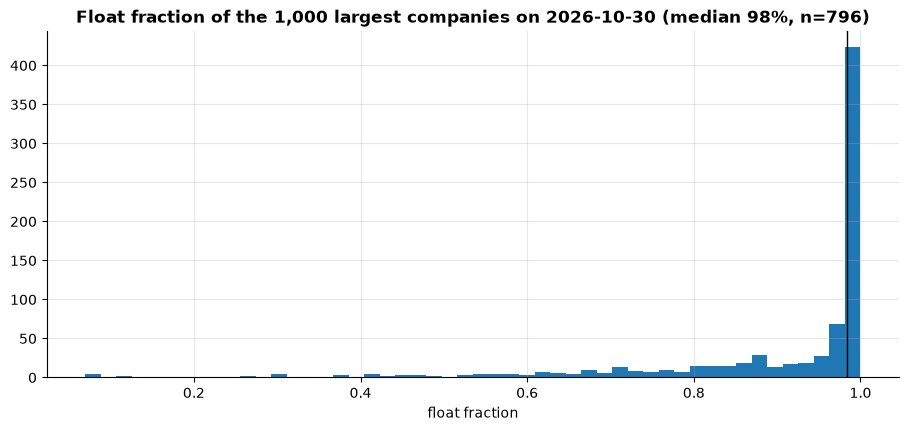

In [4]:
u = v.universe(last, top=1000, rebalance="daily").filter(pl.col("float_fraction").is_not_null())
fig, ax = plt.subplots()
ax.hist(u["float_fraction"], bins=50)
ax.axvline(u["float_fraction"].median(), color="black", lw=1)
ax.set_xlabel("float fraction")
ax.set_title(f"Float fraction of the 1,000 largest companies on {last} "
             f"(median {u['float_fraction'].median():.0%}, n={u.height})")
plt.show()

In [5]:
print("Lowest float fractions among the 200 largest:")
u.filter(pl.col("rank") <= 200).sort("float_fraction").head(15).select(
    "rank", "ticker", (pl.col("issuer_market_cap") / 1e9).round(0).alias("market_cap_bn"),
    pl.col("float_fraction").round(3), "float_date")

Lowest float fractions among the 200 largest:


rank,ticker,market_cap_bn,float_fraction,float_date
u32,str,f64,f64,date
94,"""SCCO""",150.0,0.111,2025-06-30
87,"""TMUS""",167.0,0.414,2025-06-30
46,"""DELL""",272.0,0.451,2025-08-01
13,"""WMT""",980.0,0.501,2025-07-31
153,"""NET""",99.0,0.527,2025-06-30
26,"""ORCL""",395.0,0.534,2026-05-31
43,"""CAT""",287.0,0.674,2025-12-31
195,"""EPD""",82.0,0.675,2025-06-30
152,"""HCA""",100.0,0.68,2025-06-30


Southern Copper (Grupo México), T-Mobile (Deutsche Telekom), Dell, Walmart and Oracle (Larry
Ellison) are the known controlled companies. Caterpillar is a data problem: since 2024 it dates
its float at fiscal year end instead of mid-year, so a June float is divided by a December
market cap, and the fraction reads low after a strong second half. About 2% of filings do this.

## 3 · Size ranks by market cap vs by float

Index providers weight by float. `ranks(..., by="float_market_cap")` ranks on the float-adjusted
value: controlled companies drop, widely held ones move up. Companies without a usable float
(ADRs and other foreign filers, who file no 10-K) are left out of float ranks.

In [6]:
by_cap = v.ranks(last).select("security_id", "ticker", pl.col("rank").cast(pl.Int64).alias("rank_cap"))
by_float = v.ranks(last, by="float_market_cap").select("security_id", pl.col("rank").cast(pl.Int64).alias("rank_float"))
cmp = by_cap.join(by_float, on="security_id", how="left").filter(pl.col("rank_cap") <= 100)
print(f"{cmp['rank_float'].is_null().sum()} of the top 100 by market cap have no float rank (foreign filers)")
(cmp.filter(pl.col("rank_float").is_not_null())
 .with_columns((pl.col("rank_float") - pl.col("rank_cap")).alias("change"))
 .sort("change", descending=True).head(10).drop("security_id"))

20 of the top 100 by market cap have no float rank (foreign filers)


ticker,rank_cap,rank_float,change
str,i64,i64,i64
"""SCCO""",94,460,366
"""TMUS""",87,170,83
"""DELL""",46,88,42
"""ORCL""",26,46,20
"""CAT""",43,48,5
"""GILD""",64,68,4
"""WMT""",13,15,2
"""LRCX""",39,41,2
"""CRM""",72,74,2


## 4 · Short interest: GameStop

`short_interest()` has one row per security and settlement date. By default `start`/`end`
filter on `published_date` (FINRA releases each report about 7 business days after
settlement), the date a strategy could have known the number. `si_pct_float` divides the short
position by the float-adjusted market cap: GameStop's short interest exceeded its float before
the January 2021 squeeze.

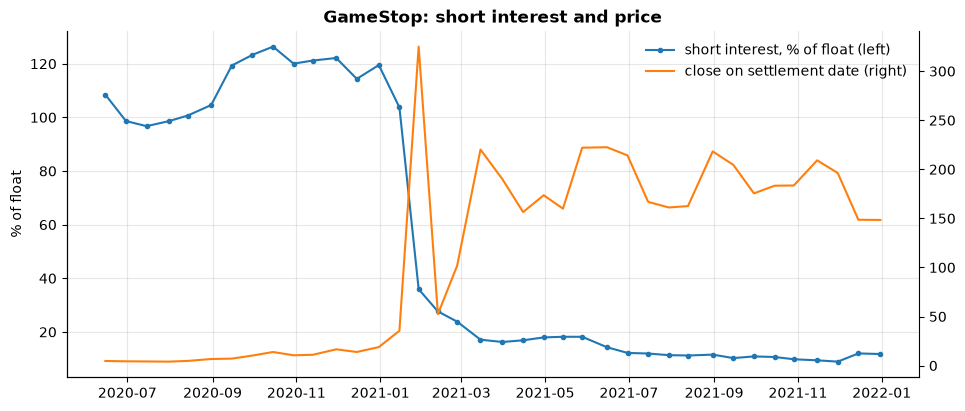

settlement_date,published_date,short_interest,days_to_cover,close,si_pct_market_cap,si_pct_float
date,date,i64,f64,f64,f64,f64
2020-12-15,2020-12-24,68127116,6.89,13.85,0.977,1.144
2020-12-31,2021-01-12,71196206,6.14,18.84,1.021,1.195
2021-01-15,2021-01-27,61782730,2.1,35.5,0.886,1.037
2021-01-29,2021-02-09,21409004,1.0,325.0,0.307,0.359
2021-02-12,2021-02-24,16468038,1.0,52.4,0.236,0.276
2021-02-26,2021-03-09,14200138,1.0,101.74,0.204,0.238


In [7]:
gme = v.short_interest("GME", start="2020-06-01", end="2021-12-31", date_by="settlement")
fig, ax = plt.subplots()
ax.plot(gme["settlement_date"], gme["si_pct_float"] * 100, marker="o", ms=3, label="short interest, % of float (left)")
ax.set_ylabel("% of float")
ax2 = ax.twinx()
ax2.plot(gme["settlement_date"], gme["close"], color="tab:orange", label="close on settlement date (right)")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title("GameStop: short interest and price")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.show()
gme.filter(pl.col("settlement_date").is_between(date(2020, 12, 1), date(2021, 2, 28))).select(
    "settlement_date", "published_date", "short_interest", "days_to_cover", "close",
    pl.col("si_pct_market_cap").round(3), pl.col("si_pct_float").round(3))

## 5 · Short interest across the market

The latest settlement date: the most shorted companies above $1 billion, and how short
interest is distributed by size.

In [8]:
with timed("short interest, all securities since 2017"):
    si = v.short_interest(start="2017-01-01")
cap = (pl.col("short_value") / pl.col("si_pct_market_cap")).alias("issuer_market_cap")
si = si.with_columns(cap)
latest = si.filter(pl.col("settlement_date") == si["settlement_date"].max())
print(f"settlement {latest['settlement_date'][0]}, published {latest['published_date'][0]}: "
      f"{latest.height:,} securities")
(latest.filter(pl.col("issuer_market_cap") >= 1e9).sort("si_pct_float", descending=True, nulls_last=True).head(12)
 .select("ticker", (pl.col("issuer_market_cap") / 1e9).round(1).alias("market_cap_bn"), "short_interest",
         pl.col("days_to_cover").round(1), pl.col("si_pct_market_cap").round(3), pl.col("si_pct_float").round(3)))

short interest, all securities since 2017: 0.62 s
settlement 2026-10-15, published 2026-10-26: 5,610 securities


ticker,market_cap_bn,short_interest,days_to_cover,si_pct_market_cap,si_pct_float
str,f64,i64,f64,f64,f64
"""WOLF""",1.4,27376417,4.2,0.525,3.001
"""KSS""",2.5,32691760,7.4,0.288,1.733
"""LCID""",1.4,99682322,9.7,0.253,0.603
"""AI""",1.9,42154732,7.6,0.272,0.539
"""MBLY""",6.1,50688439,8.3,0.062,0.502
"""SOUN""",2.1,170799103,10.0,0.397,0.468
"""BKV""",2.4,10152647,5.4,0.093,0.446
"""TGTX""",8.6,29586873,18.9,0.193,0.442
"""ULCC""",1.2,24785496,8.7,0.108,0.436


Readings far above 100% of float deserve a look before they are believed. The float fraction
comes from the last 10-K, so a company whose share count changed a lot since then (Wolfspeed
went through a restructuring in 2025) gets a stale denominator. `si_pct_market_cap` doesn't
depend on the float and is the steadier measure.

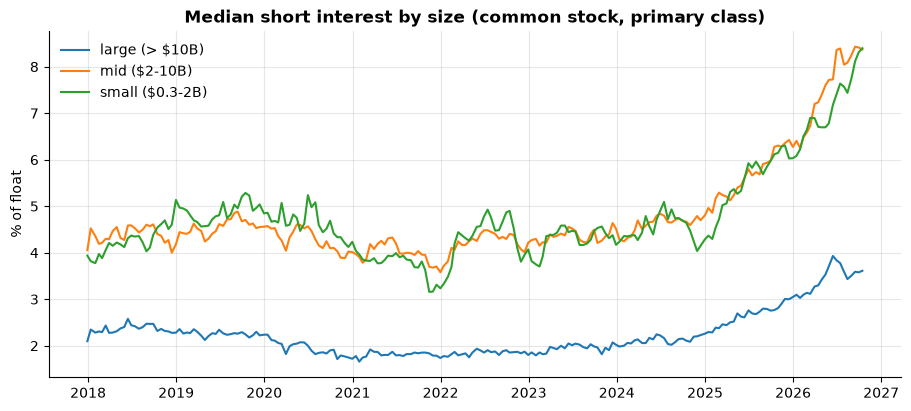

size,average_of_medians_pct
str,f64
"""large (> $10B)""",2.24
"""mid ($2-10B)""",4.78
"""small ($0.3-2B)""",4.76


In [9]:
size = (pl.when(pl.col("issuer_market_cap") >= 10e9).then(pl.lit("large (> $10B)"))
        .when(pl.col("issuer_market_cap") >= 2e9).then(pl.lit("mid ($2-10B)"))
        .when(pl.col("issuer_market_cap") >= 300e6).then(pl.lit("small ($0.3-2B)"))
        .otherwise(None).alias("size"))
med = (si.filter(pl.col("is_primary") & (pl.col("type") == "CS")).with_columns(size)
       .filter(pl.col("size").is_not_null())
       .group_by("settlement_date", "size").agg(pl.col("si_pct_float").median()).sort("settlement_date"))
fig, ax = plt.subplots()
for name in ["large (> $10B)", "mid ($2-10B)", "small ($0.3-2B)"]:
    g = med.filter(pl.col("size") == name)
    ax.plot(g["settlement_date"], g["si_pct_float"] * 100, label=name)
ax.set_ylabel("% of float")
ax.set_title("Median short interest by size (common stock, primary class)")
ax.legend()
plt.show()
med.group_by("size").agg((pl.col("si_pct_float").mean() * 100).round(2).alias("average_of_medians_pct")).sort("size")

Mid and small caps are shorted about twice as heavily as large caps: a median near 5% of float,
against about 2%.

## 6 · Daily short sale volume

`short_volume()` comes from FINRA's daily off-exchange reports: of the volume traded off
exchange (dark pools, wholesalers), how much was a short sale. `short_ratio` is typically
0.4-0.5 for every stock because market makers sell short to fill retail buy orders. It is a
flow, not a position: it says little about short interest. `off_exchange_share` is
off-exchange volume over all-venue volume from the bars.

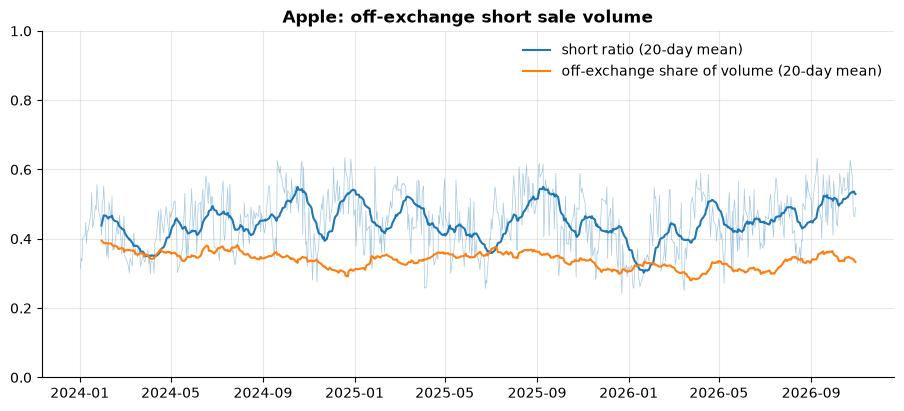

In [10]:
sv = v.short_volume("AAPL", start="2024-01-01")
roll = sv.with_columns(pl.col("short_ratio").rolling_mean(20).alias("short_ratio_20d"),
                       pl.col("off_exchange_share").rolling_mean(20).alias("off_exchange_20d"))
fig, ax = plt.subplots()
ax.plot(roll["date"], roll["short_ratio"], lw=0.5, alpha=0.4, color="tab:blue")
ax.plot(roll["date"], roll["short_ratio_20d"], color="tab:blue", label="short ratio (20-day mean)")
ax.plot(roll["date"], roll["off_exchange_20d"], color="tab:orange", label="off-exchange share of volume (20-day mean)")
ax.set_ylim(0, 1)
ax.set_title("Apple: off-exchange short sale volume")
ax.legend()
plt.show()

## 7 · Caveats

- **A few filings date the float at fiscal year end** (about 2%, Caterpillar among them),
  which understates their fraction (section 2).
- **Public float is narrower than index free float**: the SEC counts officers, directors and
  10% holders as affiliates. It is measured once a year and lags by up to 19 months.
- **Foreign filers have no public float** (20-F and 40-F covers don't carry it), so ADRs drop
  out of float ranks and `si_pct_float`; use `si_pct_market_cap` for them.
- **Multi-class companies**: `si_pct_market_cap` compares one class's short position with the
  whole company, so it reads low for a class that is a small part of the company.
- **Coverage**: vinculum keeps the equity securities of its market-cap table. ETFs,
  preferreds and OTC stocks are in `finra_sensor_array.FinraStore`. Short interest here starts
  in late 2017, daily short volume in 2009.